# I.3 — Event study of the pre-pump period

**Objective (brief I.3).** On Binance pumps quoted in BTC, with hourly data:
1. estimate a market model on $[\tau-30\,\text{d},\ \tau-72\,\text{h}]$ and compute abnormal returns (AR) and
   cumulative abnormal returns (CAR);
2. test $H_0:\ \mathbb E[\mathrm{CAR}(\tau-x\,\text{h},\tau-1\,\text{h})]=0$ for $x\in\{6,12,24,48,60,72\}$ with a
   Student test and a Wilcoxon test, and compare with the 9.5 % mean pre-pump return reported by [A1] for $x=60$;
3. study abnormal volume through $z^V_{c,t}=(\log V_{c,t}-\hat\mu_c)/\hat\sigma_c$;
4. describe minute by minute the anatomy of 20 pumps (maximum gain, time to peak, dump half-life).

In [1]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats as st

from pnd_paper import settings
from pnd_paper import stats as S
from pnd_paper.data import pd_log, binance, universe
from pnd_paper.report import Reporter, md, show, close, SERIES

warnings.filterwarnings("ignore", category=RuntimeWarning)
settings.seed_everything()
R = Reporter("I3_event_study")
XS = [6, 12, 24, 48, 60, 72]

## 1. Events and data

Relayed announcements of the same pump are merged: an **event** is a (coin, hour) pair and its time $\tau$ is the
earliest announcement among the channels, as in [A1] §4.2. Prices are Binance hourly bars in BTC (close price,
bars indexed by their opening time).

**Information horizon.** Let $t^\star$ be the opening time of the last hourly bar that closes before $\tau-1\,$h. The
window "$\tau-(x+1)\,$h to $\tau-1\,$h" of [A1] is the $x$ bars ending at $t^\star$, and the return over it is
$R^{(x)}_c=\log P_{c,t^\star}-\log P_{c,t^\star-x}=\sum_{s=t^\star-x+1}^{t^\star} r_{c,s}$.

In [2]:
ev_all = pd_log.binance_btc_events()
ev = (ev_all.assign(h=ev_all.timestamp.dt.floor("h")).sort_values("timestamp")
      .drop_duplicates(["symbol", "h"]).reset_index(drop=True))
panels = binance.build_hourly_panel(universe.universe(ev_all) + ["BTCUSDT"], universe.PANEL_START, universe.PANEL_END)
close_ = panels["close"]
qv = panels["quote_volume"]
r = np.log(close_).diff()
alts = [c for c in r.columns if c.endswith("BTC")]
n_alt = r[alts].notna().sum(axis=1)
sum_alt = r[alts].sum(axis=1)
md(f"{len(ev_all)} Binance/BTC rows → **{len(ev)} events** after merging relayed announcements "
   f"(paper: 445 Binance/BTC events in its pre-pump analysis).")

981 Binance/BTC rows → **457 events** after merging relayed announcements (paper: 445 Binance/BTC events in its pre-pump analysis).

## 2. Market model

**Market return.** The coins are quoted in BTC, so the relevant market is the BTC-denominated altcoin market. We use
the equal-weighted return of all universe coins trading at hour $t$, **excluding the target**:
$$r_{m,t}^{(-c)}=\frac{1}{N_t-1}\Big(\sum_{j\in\mathcal U_t}r_{j,t}-r_{c,t}\Big).$$

**Model.** For each event we fit by OLS on the estimation window $E=[\tau-30\,\text{d},\ \tau-72\,\text{h}]$
$$r_{c,t}=\alpha_c+\beta_c\,r_{m,t}+\varepsilon_{c,t},\qquad \varepsilon_{c,t}\sim(0,\sigma_c^2),$$
then define for $t$ outside $E$
$$AR_{c,t}=r_{c,t}-\hat\alpha_c-\hat\beta_c r_{m,t},\qquad \mathrm{CAR}_c(t_1,t_2)=\sum_{t=t_1}^{t_2}AR_{c,t}.$$
The 72-hour gap between $E$ and $\tau$ keeps the pre-pump accumulation (up to ~60 h according to [A1]) out of the
estimation. Events with fewer than 300 valid hours in $E$ are dropped.

**Robustness.** (a) *market-adjusted* returns $AR=r_c-r_m$ (i.e. $\alpha=0,\beta=1$); (b) a USD version where the
coin's USD return $r_c+r_{BTC/USDT}$ is regressed on $r_{BTC/USDT}$.

In [3]:
K_PRE, K_POST = 72, 6
rows, paths, vpaths = [], [], []
btc = r["BTCUSDT"]
for e in ev.itertuples():
    s = e.symbol
    if s not in r.columns:
        continue
    t_star = universe.last_bar_before(e.timestamp)
    if t_star not in r.index:
        continue
    i_star = r.index.get_loc(t_star)
    est = slice(i_star + 1 - 30 * 24, i_star + 1 - K_PRE)        # [tau-30d, tau-72h] in bar positions
    rc = r[s].values
    rm = ((sum_alt - r[s].fillna(0)) / (n_alt - r[s].notna().astype(int))).values
    y, x = rc[est], rm[est]
    ok = np.isfinite(y) & np.isfinite(x)
    if ok.sum() < 300:
        continue
    beta, alpha = np.polyfit(x[ok], y[ok], 1)
    resid = y[ok] - alpha - beta * x[ok]
    sigma = resid.std(ddof=2)
    win = slice(i_star + 1 - K_PRE, i_star + 1 + K_POST + 1)      # bars t*-71 .. t*+7 (event time -72..+6)
    ar = rc[win] - alpha - beta * rm[win]
    ar_ma = rc[win] - rm[win]
    yu, xu = (rc + btc.values)[est], btc.values[est]
    oku = np.isfinite(yu) & np.isfinite(xu)
    bu, au = np.polyfit(xu[oku], yu[oku], 1)
    ar_usd = (rc + btc.values)[win] - au - bu * btc.values[win]
    lv = np.log1p(qv[s].values)
    mu_v, sd_v = np.nanmean(lv[est]), np.nanstd(lv[est], ddof=1)
    zv = (lv[win] - mu_v) / sd_v
    rec = {"event_id": e.event_id, "symbol": s, "tau": e.timestamp, "alpha": alpha, "beta": beta, "sigma": sigma,
           "n_est": int(ok.sum())}
    pre = ar[:K_PRE]                              # positions 0..71 = bars t*-71 .. t*
    for xh in XS:
        seg = slice(K_PRE - xh, K_PRE)
        rec[f"CAR_{xh}"] = np.nansum(pre[seg]) if np.isfinite(pre[seg]).sum() >= 0.8 * xh else np.nan
        rec[f"CARma_{xh}"] = np.nansum(ar_ma[:K_PRE][seg]) if np.isfinite(ar_ma[:K_PRE][seg]).sum() >= 0.8 * xh else np.nan
        rec[f"CARusd_{xh}"] = np.nansum(ar_usd[:K_PRE][seg]) if np.isfinite(ar_usd[:K_PRE][seg]).sum() >= 0.8 * xh else np.nan
        raw = np.log(close_[s].iloc[i_star]) - np.log(close_[s].iloc[i_star - xh])
        rec[f"RAW_{xh}"] = raw
        rec[f"SCAR_{xh}"] = rec[f"CAR_{xh}"] / (sigma * np.sqrt(xh))
        rec[f"ZV_{xh}"] = np.nanmean(zv[:K_PRE][seg])
    rows.append(rec)
    paths.append(ar)
    vpaths.append(zv)
es = pd.DataFrame(rows)
AR = np.vstack(paths)
ZV = np.vstack(vpaths)
k_axis = np.arange(-K_PRE + 1, K_POST + 2)      # bar position relative to t* (0 = last bar before tau-1h)
R.table(es.drop(columns=["tau"]), "event_level_car", index=False)
md(f"Events with a valid estimation window: **N = {len(es)}**. Median $\\hat\\beta={es.beta.median():.2f}$ "
   f"(IQR {es.beta.quantile(.25):.2f}–{es.beta.quantile(.75):.2f}); median $\\hat\\sigma={es.sigma.median():.4f}$ per hour.")

Events with a valid estimation window: **N = 427**. Median $\hat\beta=0.88$ (IQR 0.71–1.06); median $\hat\sigma=0.0130$ per hour.

## 3. Tests on $\mathbb E[\mathrm{CAR}(\tau-x\,\text{h},\tau-1\,\text{h})]$

For each $x$, with $N$ events and $\overline{\mathrm{CAR}}=\frac1N\sum_i\mathrm{CAR}_i$:

* **Student test** — $T=\overline{\mathrm{CAR}}\big/\big(s_{\mathrm{CAR}}/\sqrt N\big)\overset{H_0}{\sim}t_{N-1}$
  (exact under normality, asymptotically valid by the CLT if the variance is finite);
* **Wilcoxon signed-rank test** — $W^+=\sum_i R_i\,\mathbf 1\{\mathrm{CAR}_i>0\}$ where $R_i$ is the rank of
  $|\mathrm{CAR}_i|$; it tests the symmetry of the distribution about 0 (median 0) and is robust to heavy tails;
* **BMP test** (Boehmer–Musumeci–Poulsen) — standardised $\mathrm{SCAR}_i=\mathrm{CAR}_i/(\hat\sigma_i\sqrt x)$ and
  $T_{BMP}=\overline{\mathrm{SCAR}}/(s_{\mathrm{SCAR}}/\sqrt N)$, which down-weights very volatile coins and is robust
  to event-induced variance;
* **Shapiro–Wilk** — $H_0$: CARs are Gaussian; a rejection motivates relying on the Wilcoxon and bootstrap results;
* a 95 % **percentile bootstrap** interval for $\mathbb E[\mathrm{CAR}]$ (5 000 resamples).

The six horizons are tested simultaneously, so p-values are adjusted with **Holm**'s step-down procedure
(family-wise error rate $\le\alpha$).

In [4]:
res = []
for xh in XS:
    c = es[f"CAR_{xh}"].dropna().values
    sc = es[f"SCAR_{xh}"].dropna().values
    t = st.ttest_1samp(c, 0.0)
    w = st.wilcoxon(c)
    b = st.ttest_1samp(sc, 0.0)
    sw = st.shapiro(c[:5000])
    lo, hi = S.bootstrap_ci(c, seed=xh)
    res.append({"x (h)": xh, "N": len(c), "mean CAR": c.mean(), "median CAR": np.median(c), "share > 0": (c > 0).mean(),
                "t": t.statistic, "p_t": t.pvalue, "W": w.statistic, "p_W": w.pvalue, "T_BMP": b.statistic,
                "p_BMP": b.pvalue, "Shapiro W": sw.statistic, "p_SW": sw.pvalue, "CI low": lo, "CI high": hi})
tab = pd.DataFrame(res)
for col in ("p_t", "p_W", "p_BMP"):
    tab[col + " (Holm)"] = S.holm(tab[col])
R.table(tab, "car_tests", index=False)
show(tab.set_index("x (h)"))

lines = []
for _, rw in tab.iterrows():
    lines.append(f"- $x={rw['x (h)']:.0f}$: $\\overline{{\\mathrm{{CAR}}}}$ = {rw['mean CAR']:.2%} "
                 f"(95 % CI [{rw['CI low']:.2%}, {rw['CI high']:.2%}]), $t({rw['N'] - 1:.0f})={rw['t']:.2f}$, "
                 f"Holm ${S.fmt_p(rw['p_t (Holm)'])}$; Wilcoxon ${S.fmt_p(rw['p_W (Holm)'])}$ (Holm); "
                 f"BMP $T={rw['T_BMP']:.2f}$, ${S.fmt_p(rw['p_BMP (Holm)'])}$ (Holm); Shapiro–Wilk ${S.fmt_p(rw['p_SW'])}$.")
md("\n".join(lines))

,N,mean CAR,median CAR,share > 0,t,p_t,W,p_W,T_BMP,p_BMP,Shapiro W,p_SW,CI low,CI high,p_t (Holm),p_W (Holm),p_BMP (Holm)
x (h),,,,,,,,,,,,,,,,,
6,425,0.02471,0.01335,0.6847,9.831,1.109e-20,1.991e+04,1.417e-23,10.47,5.521e-23,0.8048,2.81e-22,0.01985,0.0297,4.436e-20,5.667e-23,1.104e-22
12,420,0.02982,0.0152,0.6881,9.677,4.006e-20,1.959e+04,4.62e-23,10.58,2.325e-23,0.8452,6.952e-20,0.02385,0.03579,1.202e-19,9.241e-23,6.975e-23
24,424,0.03618,0.02242,0.7028,10.71,7.72e-24,1.839e+04,4.68e-26,11.63,2.679e-27,0.886,3.487e-17,0.02967,0.04292,4.632e-23,2.34e-25,1.339e-26
48,424,0.05014,0.02731,0.7193,10.35,1.517e-22,1.83e+04,3.119e-26,11.85,3.487e-28,0.8071,3.941e-22,0.04111,0.0597,7.584e-22,1.872e-25,2.092e-27
60,427,0.05826,0.0343,0.6792,9.548,1.05e-19,2.02e+04,1.683e-23,11.11,2.255e-25,0.7628,2.401e-24,0.04658,0.07058,2.1e-19,5.667e-23,9.02e-25
72,427,0.05469,0.03178,0.6604,8.351,9.569e-16,2.441e+04,7.513e-17,9.287,8.217e-19,0.7678,4.035e-24,0.04294,0.06763,9.569e-16,7.513e-17,8.217e-19


- $x=6$: $\overline{\mathrm{CAR}}$ = 2.47% (95 % CI [1.99%, 2.97%]), $t(424)=9.83$, Holm $p=4.44\times10^{-20}$; Wilcoxon $p=5.67\times10^{-23}$ (Holm); BMP $T=10.47$, $p=1.10\times10^{-22}$ (Holm); Shapiro–Wilk $p=2.81\times10^{-22}$.
- $x=12$: $\overline{\mathrm{CAR}}$ = 2.98% (95 % CI [2.39%, 3.58%]), $t(419)=9.68$, Holm $p=1.20\times10^{-19}$; Wilcoxon $p=9.24\times10^{-23}$ (Holm); BMP $T=10.58$, $p=6.98\times10^{-23}$ (Holm); Shapiro–Wilk $p=6.95\times10^{-20}$.
- $x=24$: $\overline{\mathrm{CAR}}$ = 3.62% (95 % CI [2.97%, 4.29%]), $t(423)=10.71$, Holm $p=4.63\times10^{-23}$; Wilcoxon $p=2.34\times10^{-25}$ (Holm); BMP $T=11.63$, $p=1.34\times10^{-26}$ (Holm); Shapiro–Wilk $p=3.49\times10^{-17}$.
- $x=48$: $\overline{\mathrm{CAR}}$ = 5.01% (95 % CI [4.11%, 5.97%]), $t(423)=10.35$, Holm $p=7.58\times10^{-22}$; Wilcoxon $p=1.87\times10^{-25}$ (Holm); BMP $T=11.85$, $p=2.09\times10^{-27}$ (Holm); Shapiro–Wilk $p=3.94\times10^{-22}$.
- $x=60$: $\overline{\mathrm{CAR}}$ = 5.83% (95 % CI [4.66%, 7.06%]), $t(426)=9.55$, Holm $p=2.10\times10^{-19}$; Wilcoxon $p=5.67\times10^{-23}$ (Holm); BMP $T=11.11$, $p=9.02\times10^{-25}$ (Holm); Shapiro–Wilk $p=2.40\times10^{-24}$.
- $x=72$: $\overline{\mathrm{CAR}}$ = 5.47% (95 % CI [4.29%, 6.76%]), $t(426)=8.35$, Holm $p=9.57\times10^{-16}$; Wilcoxon $p=7.51\times10^{-17}$ (Holm); BMP $T=9.29$, $p=8.22\times10^{-19}$ (Holm); Shapiro–Wilk $p=4.04\times10^{-24}$.

### Comparison with [A1]: the 9.5 % pre-pump return at $x=60$

[A1] reports the **raw** average return over the window (not an abnormal return), computed on minute mid-prices.
We report the raw return $\exp(R^{(60)})-1$, its abnormal counterpart and the robustness variants.

In [5]:
raw60 = np.expm1(es["RAW_60"].dropna())
car60 = np.expm1(es["CAR_60"].dropna())
comp = pd.DataFrame({
    "mean": [raw60.mean(), car60.mean(), np.expm1(es["CARma_60"].dropna()).mean(), np.expm1(es["CARusd_60"].dropna()).mean()],
    "median": [raw60.median(), car60.median(), np.expm1(es["CARma_60"].dropna()).median(), np.expm1(es["CARusd_60"].dropna()).median()],
    "trimmed mean (5%)": [st.trim_mean(raw60, 0.05), st.trim_mean(car60, 0.05),
                          st.trim_mean(np.expm1(es["CARma_60"].dropna()), 0.05), st.trim_mean(np.expm1(es["CARusd_60"].dropna()), 0.05)],
}, index=["raw return (as [A1])", "CAR, market model", "CAR, market-adjusted", "CAR, USD market model"])
R.table(comp, "x60_vs_paper")
show(comp, "{:.4f}")
t95 = st.ttest_1samp(raw60, 0.095)
md(f"Raw mean return at $x=60$: **{raw60.mean():.2%}** vs **9.5 %** in [A1]. Test of $H_0:\\ \\mathbb E[R]=9.5\\%$: "
   f"$t({len(raw60) - 1})={t95.statistic:.2f},\\ {S.fmt_p(t95.pvalue)}$ → {S.decision(t95.pvalue)}.")

,mean,median,trimmed mean (5%)
raw return (as [A1]),0.0639,0.0318,0.0437
"CAR, market model",0.0700,0.0349,0.0504
"CAR, market-adjusted",0.0660,0.0259,0.0450
"CAR, USD market model",0.0684,0.0390,0.0517


Raw mean return at $x=60$: **6.39%** vs **9.5 %** in [A1]. Test of $H_0:\ \mathbb E[R]=9.5\%$: $t(425)=-3.15,\ p=0.002$ → reject $H_0$ at $\alpha=0.05$.

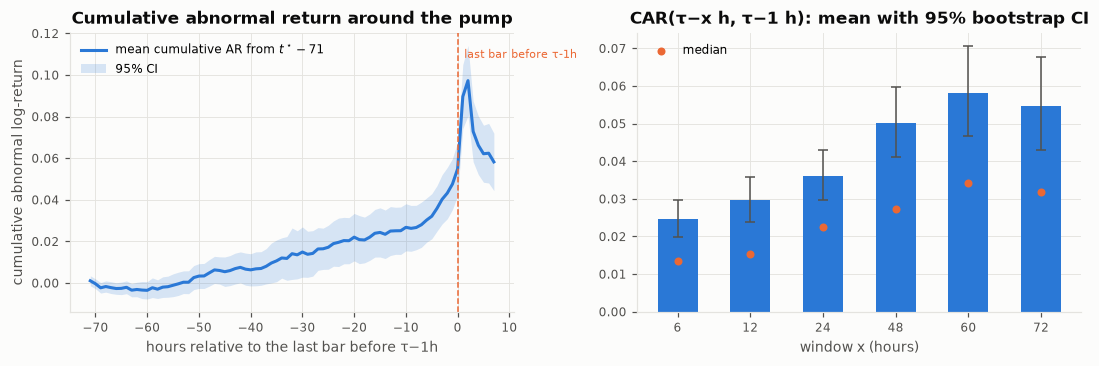

In [6]:
mean_car = np.nancumsum(np.nanmean(AR[:, :K_PRE], axis=0)[::-1])[::-1]
cum = np.nancumsum(AR, axis=1)
cum = cum - cum[:, [0]] + AR[:, [0]]
m = np.nanmean(cum, axis=0)
se = np.nanstd(cum, axis=0, ddof=1) / np.sqrt(np.isfinite(cum).sum(axis=0))
fig, axes = plt.subplots(1, 2, figsize=(10, 3.4))
axes[0].plot(k_axis, m, color=SERIES[0], label="mean cumulative AR from $t^\\star-71$")
axes[0].fill_between(k_axis, m - 1.96 * se, m + 1.96 * se, color=SERIES[0], alpha=0.18, lw=0, label="95% CI")
axes[0].axvline(0, color=SERIES[1], ls="--", lw=1)
axes[0].text(0.5, axes[0].get_ylim()[1] * 0.9, " last bar before τ-1h", fontsize=7, color=SERIES[1])
axes[0].set_xlabel("hours relative to the last bar before τ−1h")
axes[0].set_ylabel("cumulative abnormal log-return")
axes[0].set_title("Cumulative abnormal return around the pump")
axes[0].legend(loc="upper left")
axes[1].bar([str(x) for x in XS], tab["mean CAR"], color=SERIES[0], width=0.55)
axes[1].errorbar(range(len(XS)), tab["mean CAR"], yerr=[tab["mean CAR"] - tab["CI low"], tab["CI high"] - tab["mean CAR"]],
                 fmt="none", ecolor="#52514e", capsize=3, lw=1)
axes[1].scatter(range(len(XS)), tab["median CAR"], color=SERIES[1], zorder=3, s=18, label="median")
axes[1].set_xlabel("window x (hours)")
axes[1].set_title("CAR(τ−x h, τ−1 h): mean with 95% bootstrap CI")
axes[1].legend()
R.fig(fig, "car")
close(fig)

## 4. Abnormal volume

With $V_{c,t}$ the hourly quote volume (BTC) and $\hat\mu_c,\hat\sigma_c$ the mean and standard deviation of
$\log(1+V_{c,t})$ on the estimation window,
$$z^V_{c,t}=\frac{\log(1+V_{c,t})-\hat\mu_c}{\hat\sigma_c}.$$
Under "no abnormal activity", $z^V$ has mean 0 and unit variance; we test $H_0:\mathbb E[\bar z^V_{(x)}]=0$ where
$\bar z^V_{(x)}$ is the mean of $z^V$ over the window of $x$ hours.

,N,mean z,median z,t,p_t,p_W,p_t (Holm),p_W (Holm)
x (h),,,,,,,,
6,426,0.5025,0.227,9.272,9.29e-19,2.058e-14,5.574e-18,1.235e-13
12,427,0.2585,0.09271,6.197,1.357e-09,4.577e-05,6.787e-09,0.0002288
24,427,0.1356,-0.0001975,3.75,0.0002013,0.2854,0.0008053,0.8561
48,427,0.06243,-0.06371,2.064,0.03961,0.51,0.1188,0.897
60,427,0.05155,-0.08398,1.823,0.06897,0.4485,0.1379,0.897
72,427,0.03165,-0.0741,1.198,0.2314,0.1766,0.2314,0.7064


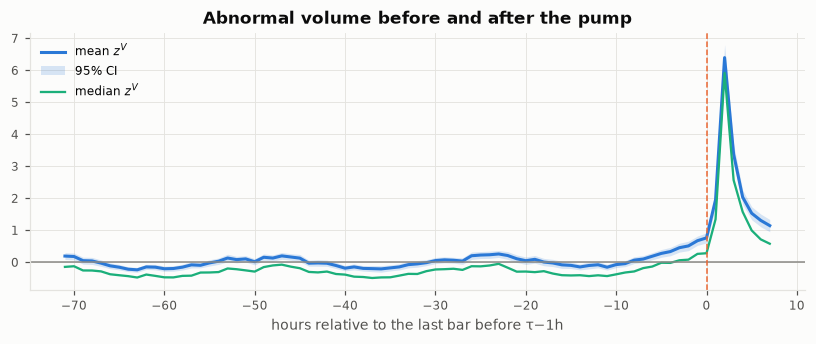

Mean $z^V$ is -0.03 on average between 72 and 48 hours before $t^\star$, 0.50 over the last 6 bars before $t^\star$, and 2.6 once the pump starts. Across windows, abnormal volume is significant (Holm, Student) for $x\le$ 24 h only: the volume build-up is concentrated in the last hours, whereas the price drift spans days.

In [7]:
zres = []
for xh in XS:
    z = es[f"ZV_{xh}"].dropna().values
    t = st.ttest_1samp(z, 0.0)
    w = st.wilcoxon(z)
    zres.append({"x (h)": xh, "N": len(z), "mean z": z.mean(), "median z": np.median(z), "t": t.statistic, "p_t": t.pvalue,
                 "p_W": w.pvalue})
ztab = pd.DataFrame(zres)
ztab["p_t (Holm)"] = S.holm(ztab.p_t)
ztab["p_W (Holm)"] = S.holm(ztab.p_W)
R.table(ztab, "volume_tests", index=False)
show(ztab.set_index("x (h)"))
zm = np.nanmean(ZV, axis=0)
zse = np.nanstd(ZV, axis=0, ddof=1) / np.sqrt(np.isfinite(ZV).sum(axis=0))
zmed = np.nanmedian(ZV, axis=0)
fig, ax = plt.subplots(figsize=(7.5, 3.2))
ax.plot(k_axis, zm, color=SERIES[0], label="mean $z^V$")
ax.fill_between(k_axis, zm - 1.96 * zse, zm + 1.96 * zse, color=SERIES[0], alpha=0.18, lw=0, label="95% CI")
ax.plot(k_axis, zmed, color=SERIES[2], lw=1.5, label="median $z^V$")
ax.axhline(0, color="#8a8985", lw=1)
ax.axvline(0, color=SERIES[1], ls="--", lw=1)
ax.set_xlabel("hours relative to the last bar before τ−1h")
ax.set_title("Abnormal volume before and after the pump")
ax.legend(loc="upper left")
R.fig(fig, "abnormal_volume")
close(fig)
early = zm[(k_axis >= -71) & (k_axis <= -48)].mean()
late = zm[(k_axis >= -5) & (k_axis <= 0)].mean()
post = zm[k_axis >= 2].mean()
md(f"Mean $z^V$ is {early:.2f} on average between 72 and 48 hours before $t^\\star$, {late:.2f} over the last 6 bars "
   f"before $t^\\star$, and {post:.1f} once the pump starts. Across windows, abnormal volume is significant (Holm, "
   f"Student) for $x\\le$ {int(ztab.loc[ztab['p_t (Holm)'] < 0.05, 'x (h)'].max())} h only: the volume build-up is "
   "concentrated in the last hours, whereas the price drift spans days.")

## 5. Minute anatomy of 20 pumps

For 20 events drawn at random (seeded) we download the Binance 1-minute bars. With $p_0$ the open of the minute
containing $\tau$, $H_s$ the high and $C_s$ the close of minute $s\ge0$ after $\tau$:

* **maximum gain** $G=\max_{0\le s\le 60}H_s/p_0-1$;
* **time to peak** $s^\star=\arg\max_{0\le s\le60}H_s$ (minutes);
* **dump half-life** $h_{1/2}=\min\{s>s^\star: C_s\le p_0+\tfrac12(H_{s^\star}-p_0)\}-s^\star$, the minutes needed
  to give back half of the gain (censored at 120 min).

,coin,date,max gain,time to peak (min),half-life (min),gain at +60 min
event,,,,,,
865,FXS,2021-09-19 17:00,0.898,1,5,0.352
241,ARK,2019-09-12 14:59,0.081,31,22,0.032
681,MDA,2021-02-10 21:00,2.822,0,1,-0.058
287,LRC,2019-11-16 05:01,0.011,0,1,-0.008
875,EZ,2021-10-03 17:00,0.404,0,1,-0.219
882,SKY,2021-10-05 15:00,0.363,8,2,0.001
967,OAX,2021-12-28 15:00,0.070,0,1,-0.252
848,SNX,2021-08-24 12:30,0.006,16,1,-0.016
766,DLT,2021-05-30 16:00,0.152,60,1,-0.031


,mean,50%,min,max
max gain,0.333,0.127,0.006,2.822
time to peak (min),7.750,1.000,0.000,60.000
half-life (min),3.600,1.000,1.000,22.000
gain at +60 min,-0.009,-0.010,-0.252,0.352


Over 20 pumps: median maximum gain **12.7%** (max 282%), median time to peak **1 min**, median dump half-life **1 min** (0 censored), and one hour later the median price is **-1.0%** relative to $p_0$.

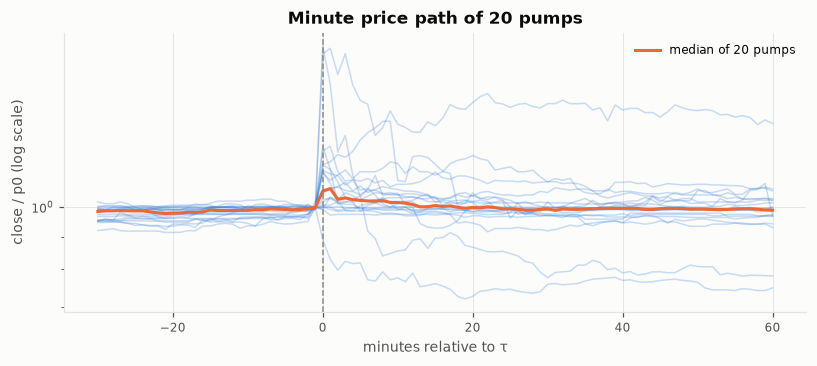

In [8]:
rng = np.random.default_rng(settings.SEED)
sample = ev[ev.symbol.isin(es.symbol)].iloc[rng.choice(len(ev[ev.symbol.isin(es.symbol)]), 20, replace=False)]
anat, curves = [], []
for e in sample.itertuples():
    k = binance.load_klines(e.symbol, "1m", e.timestamp - pd.Timedelta(hours=2), e.timestamp + pd.Timedelta(hours=3))
    if k.empty:
        continue
    t0 = e.timestamp.floor("min")
    if t0 not in k.index:
        continue
    i0 = k.index.get_loc(t0)
    p0 = k.open.iloc[i0]
    hi = k.high.iloc[i0:i0 + 61].values
    s_star = int(np.argmax(hi))
    peak = hi[s_star]
    after = k.close.iloc[i0 + s_star + 1:i0 + s_star + 121].values
    half = p0 + 0.5 * (peak - p0)
    hit = np.where(after <= half)[0]
    anat.append({"event": e.event_id, "coin": e.coin, "date": e.timestamp.strftime("%Y-%m-%d %H:%M"),
                 "max gain": peak / p0 - 1, "time to peak (min)": s_star,
                 "half-life (min)": (hit[0] + 1) if len(hit) else np.nan,
                 "gain at +60 min": k.close.iloc[min(i0 + 60, len(k) - 1)] / p0 - 1})
    seg = k.close.iloc[max(i0 - 30, 0):i0 + 61] / p0
    curves.append(pd.Series(seg.values, index=np.arange(len(seg)) - min(30, i0)))
anat = pd.DataFrame(anat)
R.table(anat, "anatomy_20_pumps", index=False)
show(anat.set_index("event"), "{:.3f}")
desc = anat[["max gain", "time to peak (min)", "half-life (min)", "gain at +60 min"]].describe().T[["mean", "50%", "min", "max"]]
show(desc, "{:.3f}")
md(f"Over {len(anat)} pumps: median maximum gain **{anat['max gain'].median():.1%}** (max {anat['max gain'].max():.0%}), "
   f"median time to peak **{anat['time to peak (min)'].median():.0f} min**, median dump half-life "
   f"**{anat['half-life (min)'].median():.0f} min** ({anat['half-life (min)'].isna().sum()} censored), and one hour "
   f"later the median price is **{anat['gain at +60 min'].median():+.1%}** relative to $p_0$.")

fig, ax = plt.subplots(figsize=(7.5, 3.4))
for c in curves:
    ax.plot(c.index, c.values, color=SERIES[0], alpha=0.25, lw=1)
med = pd.concat(curves, axis=1).median(axis=1)
ax.plot(med.index, med.values, color=SERIES[1], lw=2, label="median of 20 pumps")
ax.axvline(0, color="#8a8985", lw=1, ls="--")
ax.set_yscale("log")
ax.set_xlabel("minutes relative to τ")
ax.set_ylabel("close / p0 (log scale)")
ax.set_title("Minute price path of 20 pumps")
ax.legend()
R.fig(fig, "anatomy")
close(fig)

## 6. Interpretation (QUICK run; this notebook has no QUICK/FULL difference)

* **A significant pre-pump drift exists at every horizon.** The mean CAR is positive and grows with the window:
  about 2.5 % over the last 6 hours, 3.6 % over 24 h and a maximum of about 5.8 % at $x=60$, before slightly
  decreasing at $x=72$. All three tests (Student, Wilcoxon, BMP) reject $H_0:\mathbb E[\mathrm{CAR}]=0$ at any
  conventional level after the Holm correction (p-values below $10^{-15}$). Two thirds or more of the events show
  a positive CAR, so the effect is not driven by a few outliers. The peak at $x=60$ matches the paper's statement
  that "buy-in behaviour starts within 60 hours" (§1, §4.2): extending the window to 72 h only adds noise.
* **The distribution is far from Gaussian** (Shapiro–Wilk p-values $<10^{-16}$, heavy right tail), so the
  Wilcoxon and bootstrap results are the reliable ones; they agree with the t-test.
* **Comparison with the 9.5 % of [A1].** Our raw mean return at $x=60$ is about 6.4 % (median 3.2 %), and
  $H_0:\mathbb E[R]=9.5\,\%$ is rejected ($p\approx0.002$). Plausible reasons: [A1] uses minute mid-prices and its own
  merging of 445 events, while we use hourly closes; and a mean of heavy-tailed returns is unstable, as the gap
  between the mean, the trimmed mean and the median shows. The qualitative finding, a significant positive drift
  that peaks around 60 hours, is reproduced.
* **The drift is not a market effect.** Market-model, market-adjusted and USD-denominated CARs are all within
  about one percentage point of the raw return: the BTC-quoted altcoin market does not explain the run-up.
* **Volume moves later than price.** Abnormal volume is significant only for windows of 24 hours or less and is
  strongest over the last 6 hours (mean $z^V\approx0.5$), while it is nil 48 to 72 hours before. The early
  price drift with normal volume is consistent with discreet accumulation by insiders (small orders spread over
  days), followed by a visible volume surge as the announcement approaches.
* **Anatomy.** The pump itself is extremely short. In the 20 sampled pumps the price peaks within one minute in
  most cases (median time to peak 1 min), half of the gain is lost within a minute or two (median half-life
  1 min), and one hour later the price is back near its starting level (median $-1\,\%$). Gains are very uneven:
  median 13 %, but up to 280 % (MDA, February 2021). Only participants who buy *before* the announcement can
  profit, which is the core argument of [A1] for predicting the target coin in advance.

**Limitations.** Hourly bars blur the last hour before $\tau$; overlapping event windows of different coins
share market shocks, so the cross-sectional tests are slightly optimistic. The minute anatomy sample is small
(20 pumps) and is descriptive only.